    Folie 35 Hausaufgabe

In [54]:
import pandas as pd
forest_fires = pd.read_excel(pd.ExcelFile("C:\\0 Eigene Dateien\\9 Lehre\\2019 Einführung in Data Science\\4. Veranstaltung\\Waldbrände.xlsx"))
forest_fires_filtered=forest_fires.drop([0], axis=0)
forest_fires_filtered.replace(["Janeiro", "Fevereiro", "Março", "Abril","Maio","Junho", "Julho","Agosto","Setembro","Outubro","Novembro","Dezembro"], [1, 2, 3,4,5,6,7,8,9,10,11,12], inplace = True)
forest_fires_filtered.rename(columns={"number.1": "absolute"}, inplace = True)
forest_fires_filtered=forest_fires_filtered.drop("number", axis=1)
forest_fires_filtered

,year,state,month,absolute,date
1,1998,Acre,1,0,1998-01-01
2,1999,Acre,1,0,1999-01-01
3,2000,Acre,1,0,2000-01-01
4,2001,Acre,1,0,2001-01-01
5,2002,Acre,1,0,2002-01-01
...,...,...,...,...,...
393,2010,Alagoas,8,1,2010-01-01
394,2011,Alagoas,8,4,2011-01-01
395,2012,Alagoas,8,0,2012-01-01
396,2013,Alagoas,8,0,2013-01-01


In [55]:
forest_fires_filtered.describe()

,year,month,absolute
count,397.000000,397.000000,397.000000
mean,2007.435768,5.654912,430.564232
std,5.747114,3.197901,3198.885717
min,1998.000000,1.000000,0.000000
25%,2002.000000,3.000000,0.000000
50%,2007.000000,5.000000,4.000000
75%,2012.000000,8.000000,38.000000
max,2017.000000,12.000000,43679.000000


In [56]:
forest_fires_filtered["absolute"].mean()>forest_fires_filtered["absolute"].median()>forest_fires_filtered["absolute"].mode()[0]

True

<AxesSubplot:>

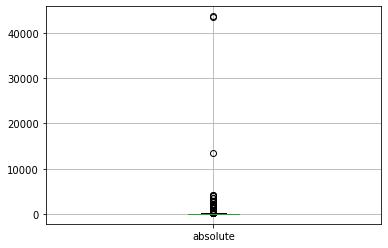

In [57]:
forest_fires_filtered.boxplot(["absolute"])

array([[<AxesSubplot:title={'center':'year'}>,
        <AxesSubplot:title={'center':'month'}>],
       [<AxesSubplot:title={'center':'absolute'}>,
        <AxesSubplot:title={'center':'date'}>]], dtype=object)

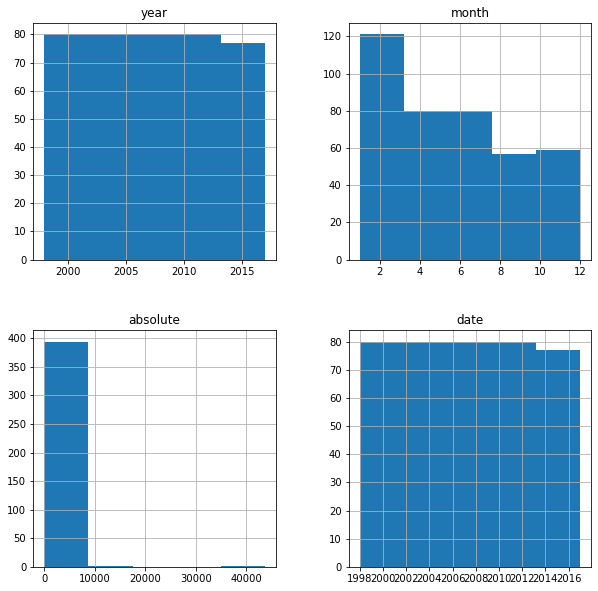

In [58]:
import numpy as np
forest_fires_filtered.hist(bins= int(np.sqrt(26)), figsize =(10,10))

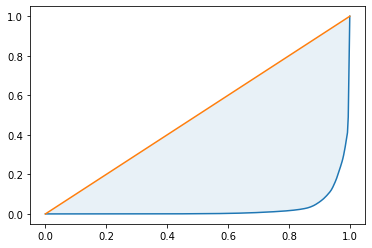

In [59]:
from matplotlib import pyplot as plt
def lorenz_curve(X):
    #X=np.append(X,[0])
    X.sort()
    Y_lorenz = X.cumsum() / X.sum()
    X_lorenz = np.arange(Y_lorenz.size)/(Y_lorenz.size-1)
    plt.plot(X_lorenz,Y_lorenz)
    Y = X_lorenz
    plt.fill_between(X_lorenz, Y_lorenz, Y, alpha = 0.1)
    plt.plot(X_lorenz, X_lorenz)
lorenz_curve(forest_fires_filtered["absolute"].to_numpy())

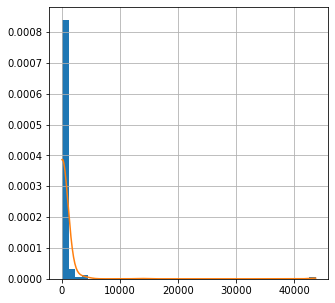

In [60]:
from matplotlib.gridspec import GridSpec
from scipy import stats
def plot_kde_approx(data):
    fig = plt.figure(figsize=(5,5))
    gs = GridSpec(1,1)
    a1 = fig.add_subplot(gs[0,0])
    xmin, xmax = min(data),max(data)
    positions = np.linspace(xmin, xmax, len(data))
    kde = stats.gaussian_kde(data)
    pd.Series(data).hist(ax= a1, bins = int(2*np.sqrt(len(data))), density=1)
    a1.plot(positions,kde(positions))
    plt.show()
    
plot_kde_approx(forest_fires_filtered["absolute"].to_numpy())

Folie 43 Kontigenztabelle

In [61]:
import numpy as np
import pandas as pd
parties = ["cdu", "spd","gruene", "fdp", "afd"]
genders = ["male","female"]
n = 50
gender = np.random.choice(genders,n)
party = np.random.choice(parties,n)
df = pd.DataFrame({"gender":gender, "party":party}) 
df_abs = df.groupby(['gender', 'party']).size().unstack()
df_abs

party,afd,cdu,fdp,gruene,spd
gender,,,,,
female,4,5,8,5,4
male,2,3,8,4,7


In [62]:
df_rel = df_abs/df_abs.sum().sum()
df_rel

party,afd,cdu,fdp,gruene,spd
gender,,,,,
female,0.08,0.10,0.16,0.10,0.08
male,0.04,0.06,0.16,0.08,0.14


In [63]:
election = pd.DataFrame({"gender":gender, "party":party}) 

pd.crosstab(index = election["gender"], columns = election["party"], margins = True, normalize = True) 

party,afd,cdu,fdp,gruene,spd,All
gender,,,,,,
female,0.08,0.10,0.16,0.10,0.08,0.52
male,0.04,0.06,0.16,0.08,0.14,0.48
All,0.12,0.16,0.32,0.18,0.22,1.00


Folie 42 3D-Säulendiagramm

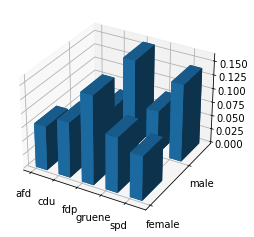

In [64]:
from mpl_toolkits.mplot3d import Axes3D 

import matplotlib.pyplot as plt
import numpy as np

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
dz = np.array(df_rel.T.to_numpy())
dim_x = dz.shape[0]
dim_y = dz.shape[1]

# Construct arrays for the anchor positions of the 16 bars.
xpos, ypos = np.meshgrid(np.arange(dim_x), np.arange(dim_y), indexing="ij")
xpos = xpos.ravel()
ypos = ypos.ravel()
dz = dz.ravel()
dx = 0.5
dy = 0.5
zpos = 0

ax.bar3d(xpos, ypos, zpos, dx, dy, dz, zsort='average')
plt.xticks(np.arange(dim_x),df_rel.T.index)
plt.yticks(np.arange(dim_y),df_rel.index)

plt.show()

Folie 46 Bedingte realtive Häufigkeiten

In [65]:
df_cond =  df_abs.T/df_abs.T.sum()
df_cond

gender,female,male
party,,
afd,0.153846,0.083333
cdu,0.192308,0.125000
fdp,0.307692,0.333333
gruene,0.192308,0.166667
spd,0.153846,0.291667


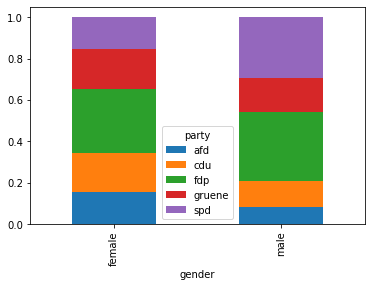

In [66]:
df_cond.T.plot.bar(stacked=True);

Folie 49 Chancenverhältnis

In [67]:
import scipy.stats as stats

table = df_abs.T.loc[["cdu", "spd"]]
print(table)
oddsratio, _ = stats.fisher_exact(table)
print("OddsR: ", oddsratio)

gender  female  male
party               
cdu          5     3
spd          4     7
OddsR:  2.9166666666666665


Folie 50

<AxesSubplot:xlabel='gender', ylabel='party'>

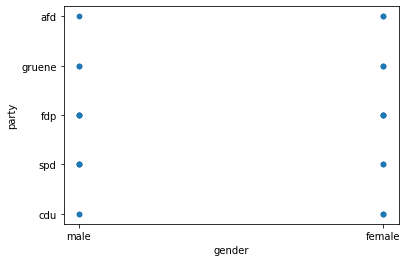

In [68]:
df = pd.DataFrame({"gender":gender, "party":party}) 
df.plot.scatter("gender", "party")

Folie 53 Scatterplot-Matrix

array([[<Axes: xlabel='Price', ylabel='Price'>,
        <Axes: xlabel='Price_sqm', ylabel='Price'>,
        <Axes: xlabel='sqm', ylabel='Price'>,
        <Axes: xlabel='rooms', ylabel='Price'>],
       [<Axes: xlabel='Price', ylabel='Price_sqm'>,
        <Axes: xlabel='Price_sqm', ylabel='Price_sqm'>,
        <Axes: xlabel='sqm', ylabel='Price_sqm'>,
        <Axes: xlabel='rooms', ylabel='Price_sqm'>],
       [<Axes: xlabel='Price', ylabel='sqm'>,
        <Axes: xlabel='Price_sqm', ylabel='sqm'>,
        <Axes: xlabel='sqm', ylabel='sqm'>,
        <Axes: xlabel='rooms', ylabel='sqm'>],
       [<Axes: xlabel='Price', ylabel='rooms'>,
        <Axes: xlabel='Price_sqm', ylabel='rooms'>,
        <Axes: xlabel='sqm', ylabel='rooms'>,
        <Axes: xlabel='rooms', ylabel='rooms'>]], dtype=object)

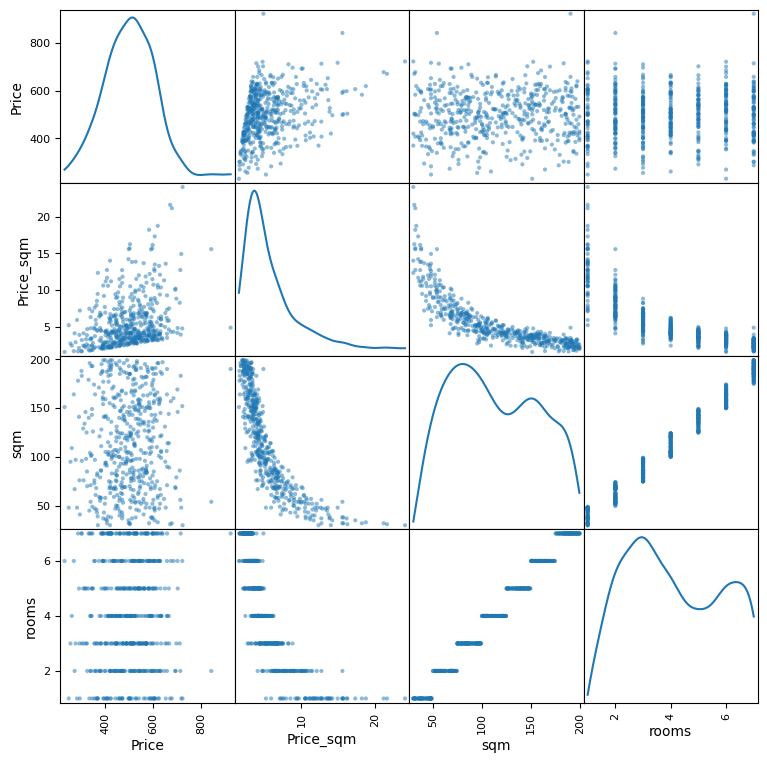

In [8]:
import numpy as np
import pandas as pd
amount_flats = 500
prices =  np.random.normal(loc = 500, scale = 100, size=amount_flats).round(2)
sqm = np.random.randint(30,200,amount_flats)
prices_sqm = (prices/sqm).round(2)
amount_room = (sqm/25).astype(int)
data = {"Price":prices, "Price_sqm":prices_sqm, "sqm":sqm, "rooms":amount_room}                           
df_abs = pd.DataFrame(data)

from pandas.plotting import scatter_matrix
scatter_matrix(df_abs, figsize=(9, 9), diagonal='kde')

Folie 61 Bravias-Pearson- Korrelationskoeffizienten

In [70]:
df_abs.corr("pearson") 

,Price,Price_sqm,sqm,rooms
Price,1.000000,0.340084,-0.020428,-0.011419
Price_sqm,0.340084,1.000000,-0.832646,-0.824317
sqm,-0.020428,-0.832646,1.000000,0.989801
rooms,-0.011419,-0.824317,0.989801,1.000000


Folie 65 Spearman-Korrelationskoeffizienten

In [71]:
df_abs.corr("spearman") 

,Price,Price_sqm,sqm,rooms
Price,1.000000,0.385706,-0.020359,-0.012175
Price_sqm,0.385706,1.000000,-0.910560,-0.899537
sqm,-0.020359,-0.910560,1.000000,0.989162
rooms,-0.012175,-0.899537,0.989162,1.000000


Folie 67 Φ-Koeffizient

In [25]:
import numpy as np
from sklearn.metrics import matthews_corrcoef
n = 30
y_sample = np.random.choice((0,1),n)
cond = (np.random.rand(n)>=0.5)
y_pred = np.logical_xor(y_sample, cond).astype(int)

print(y_sample)
print(cond.astype(int))
print(y_pred)

matthews_corrcoef(y_sample, y_pred)

[0 0 0 0 0 0 1 1 0 0 1 1 1 1 0 1 0 1 0 0 1 1 0 0 0 1 1 1 1 0]
[0 0 0 1 0 1 0 0 1 1 1 0 0 0 0 1 0 1 1 1 0 0 0 1 1 0 1 1 1 1]
[0 0 0 1 0 1 1 1 1 1 0 1 1 1 0 0 0 0 1 1 1 1 0 1 1 1 0 0 0 1]


0.008988968316207744

In [27]:
data = pd.DataFrame({"sample":y_sample, "prediction":y_pred}).groupby(["sample","prediction"]).size().unstack()
data

prediction,0,1
sample,,
0,7,9
1,6,8


In [28]:
phi=(data[0][0]*data[1][1]-data[0][1]*data[1][0])/np.sqrt(data.sum(axis=1).values[0]*data.sum(axis=1).values[1]*data.sum(axis=0).values[0]*data.sum(axis=0).values[1])
phi

np.float64(0.008988968316207744)

Folie 73 Lineare Regression

In [74]:
def lin_reg(X,Y):
    x_mean= np.mean(X)
    y_mean= np.mean(Y)    
    n = len(X)
    b=(np.sum(X*Y)-n*y_mean*x_mean)/(np.sum(X**2)-n*x_mean**2)
    a = y_mean-b*x_mean
    return a,b

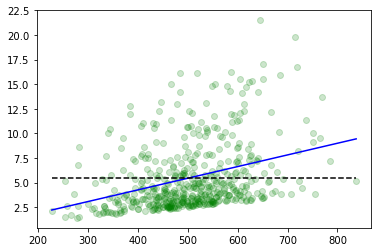

In [75]:
X_Train = df_abs["Price"].to_numpy()
Y_Train = df_abs["Price_sqm"].to_numpy()
a,b = lin_reg(X_Train,Y_Train)

x = np.linspace(np.min(X_Train), np.max(X_Train), 500)
y = a+b*x
y_mean = np.zeros_like(Y_Train)
y_mean += np.mean(Y_Train)
plt.plot(X_Train, Y_Train, "go", alpha = 0.2)
plt.plot(x,y, linestyle="-", color ="blue")
plt.plot(x,y_mean, linestyle="--", color ="black")

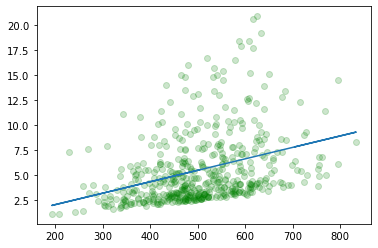

In [62]:
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

lr = LinearRegression()
X_Train = df_abs["Price"].values.reshape(-1, 1)
Y_Train = df_abs["Price_sqm"].values.reshape(-1, 1)
lr.fit(X_Train, Y_Train)
plt.scatter(X_Train,Y_Train, color = "green", alpha = 0.2)
plt.plot(X_Train,lr.predict(X_Train))

Folie 77 Bestimmtheitsmaß

In [63]:
lr.score(X_Train, Y_Train)

0.12083127588549958

0.9781009054234597

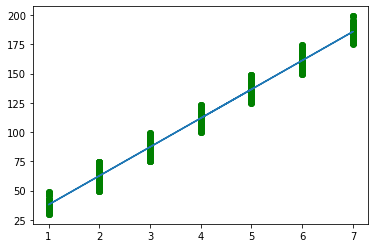

In [65]:
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

lr = LinearRegression()
X_Train = df_abs["rooms"].values.reshape(-1, 1)
Y_Train = df_abs["sqm"].values.reshape(-1, 1)
lr.fit(X_Train, Y_Train)
plt.scatter(X_Train,Y_Train, color = "green")
plt.plot(X_Train,lr.predict(X_Train))

lr.score(X_Train, Y_Train)